# 🚆 Level Crossing Collision Risk: ML for Rail-Road Interface Safety

**Author:** Dean Wang | Lead Data & AI Engineer

**Government:** ONRSR, ATSB, state road & rail authorities, Level Crossing Removal Project (Vic)

Dataset: sklearn synthetic — NO dataset needed.

---

Generated: (2200, 13)


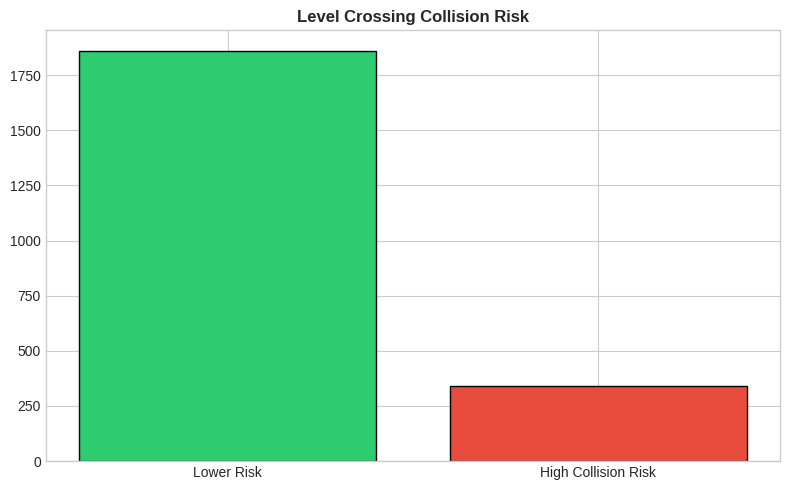

AU: 23,000+ level crossings, 5,000+ passive (signs only). Victoria removed 80+ crossings since 2015.


In [1]:
import warnings,time,numpy as np,pandas as pd,matplotlib.pyplot as plt,seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score,f1_score,roc_auc_score,confusion_matrix,classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings('ignore');plt.style.use('seaborn-v0_8-whitegrid')
X_arr,y=make_classification(n_samples=2200,n_features=12,n_informative=9,n_classes=2,weights=[0.85,0.15],random_state=227)
names=['daily_road_traffic','daily_train_movements','protection_type_passive','sight_distance_m','approach_road_speed','heavy_vehicle_pct','train_speed_kmh','crossing_angle_skew','near_miss_reports_5yr','school_bus_route','sun_glare_exposure','road_surface_condition']
df=pd.DataFrame(X_arr,columns=names);df['high_collision_risk']=y;tc='high_collision_risk'
print(f"Generated: {df.shape}");labels=['Lower Risk','High Collision Risk'];colors=['#2ecc71','#e74c3c']
fig,ax=plt.subplots(figsize=(8,5));vc=df[tc].value_counts().sort_index()
ax.bar(range(2),vc.values,color=colors,edgecolor='black');ax.set_xticks(range(2));ax.set_xticklabels(labels)
ax.set_title('Level Crossing Collision Risk',fontweight='bold');plt.tight_layout();plt.savefig('t.png',dpi=150);plt.show()
print("AU: 23,000+ level crossings, 5,000+ passive (signs only). Victoria removed 80+ crossings since 2015.")

LogReg: Acc=0.8895 F1=0.5226 AUC=0.8352
RF: Acc=0.9227 F1=0.6783 AUC=0.9145
XGB: Acc=0.9314 F1=0.7398 AUC=0.9332
LGBM: Acc=0.9345 F1=0.7523 AUC=0.9383
Best: LGBM


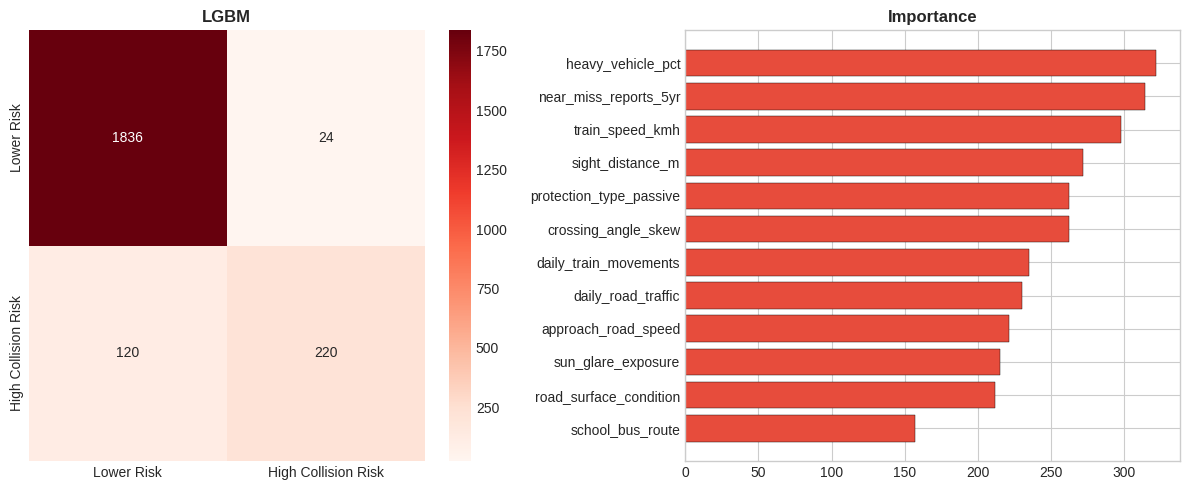

                     precision    recall  f1-score   support

         Lower Risk       0.94      0.99      0.96      1860
High Collision Risk       0.90      0.65      0.75       340

           accuracy                           0.93      2200
          macro avg       0.92      0.82      0.86      2200
       weighted avg       0.93      0.93      0.93      2200

DEPLOYMENT: LGBM AUC=0.9383 | ALCAM crossing data -> upgrade/removal prioritisation (boom gates, grade separation)


In [2]:
nums=[c2 for c2 in df.columns if c2!=tc];X=df[nums];y2=df[tc].values
try:
    from xgboost import XGBClassifier
except: XGBClassifier=None
try:
    from lightgbm import LGBMClassifier
except: LGBMClassifier=None
models={'LogReg':LogisticRegression(max_iter=2000,random_state=42),'RF':RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)}
if XGBClassifier: models['XGB']=XGBClassifier(n_estimators=100,random_state=42,eval_metric='logloss',use_label_encoder=False,verbosity=0,n_jobs=-1)
if LGBMClassifier: models['LGBM']=LGBMClassifier(n_estimators=100,random_state=42,verbose=-1,n_jobs=-1,force_col_wise=True)
skf=StratifiedKFold(3,shuffle=True,random_state=42);Xa=X.values;results={}
for mn,mod in models.items():
    fa,ff,fu=[],[],[];fp=np.zeros(len(y2),dtype=int)
    for fi,(ti,vi) in enumerate(skf.split(Xa,y2)):
        m2=type(mod)(**mod.get_params());m2.fit(Xa[ti],y2[ti]);yp=m2.predict(Xa[vi]);yb=m2.predict_proba(Xa[vi])[:,1]
        fp[vi]=yp;fa.append(accuracy_score(y2[vi],yp));ff.append(f1_score(y2[vi],yp));fu.append(roc_auc_score(y2[vi],yb))
    results[mn]={'acc':np.mean(fa),'f1':np.mean(ff),'auc':np.mean(fu),'preds':fp}
    print(f"{mn}: Acc={np.mean(fa):.4f} F1={np.mean(ff):.4f} AUC={np.mean(fu):.4f}")
best=max(results,key=lambda k:results[k]['auc']);print(f"Best: {best}")
bp=results[best]['preds'];cm=confusion_matrix(y2,bp)
fig,axes=plt.subplots(1,2,figsize=(12,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Reds',xticklabels=labels,yticklabels=labels,ax=axes[0]);axes[0].set_title(f'{best}',fontweight='bold')
tm={k:v for k,v in models.items() if k!='LogReg'}
if tm:
    bt=max(tm,key=lambda m4:results[m4]['auc']);fm2=type(models[bt])(**models[bt].get_params());fm2.fit(Xa,y2)
    fi=pd.DataFrame({'Feature':X.columns,'Imp':fm2.feature_importances_}).sort_values('Imp')
    axes[1].barh(fi['Feature'],fi['Imp'],color='#e74c3c',edgecolor='black',linewidth=0.3);axes[1].set_title('Importance',fontweight='bold')
plt.tight_layout();plt.savefig('r.png',dpi=150);plt.show()
print(classification_report(y2,bp,target_names=labels))
br=results[best];print(f"DEPLOYMENT: {best} AUC={br['auc']:.4f} | ALCAM crossing data -> upgrade/removal prioritisation (boom gates, grade separation)")